# 04 · Final holdout evaluation

Evaluate the frozen Naive Bayes pipeline selected in Notebook 3 on the reserved 20% holdout. This notebook does **not** refit, tune, select a threshold, or use holdout results to change the model. Run it only after Notebook 3 has completed and saved its model and holdout IDs.

The measured target is the dataset label (`Fake.csv` → `fake`, `True.csv` → `real`). This evaluation estimates performance on a random holdout from the same deduplicated dataset. It does not establish truth verification or performance on future articles or unseen publishers.


## 1. Evaluation plan and safeguards

- Recreate the exact title/body normalization and SHA-256 article IDs used in Notebook 3.
- Load the saved holdout ID list and verify it is unique, present in the current raw data, and non-overlapping with the remaining training IDs.
- Load the frozen vectorizer-plus-classifier pipeline. Do not train or tune it here.
- Score the reserved articles once. Macro F1 is the primary metric; accuracy, macro precision/recall, per-class results, and a confusion matrix provide context.
- Save aggregate metrics and per-article predictions without article text. Inspect errors locally if needed; do not use these results to tune and then report the same holdout as an unbiased final evaluation.


In [1]:
from datetime import datetime, timezone
from hashlib import sha256
from pathlib import Path
import importlib.metadata as package_metadata
import json
import platform

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)


## 2. Load the source data and saved evaluation artifacts

Only `title` and `text` are model inputs. `subject`, `date`, and source-file fields are excluded, matching Notebook 3. Reconstruct the content hash after exact title/body deduplication, then match holdout rows by that stable ID rather than by row position.


In [2]:
cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents] if (p / 'data' / 'raw' / 'News').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not locate data/raw/News from the notebook working directory.')

raw_dir = PROJECT_ROOT / 'data' / 'raw' / 'News'
model_path = PROJECT_ROOT / 'models' / 'final_naive_bayes_pipeline.joblib'
holdout_ids_path = PROJECT_ROOT / 'outputs' / 'holdout_article_ids.csv'
for required_path in [raw_dir / 'Fake.csv', raw_dir / 'True.csv', model_path, holdout_ids_path]:
    if not required_path.exists():
        raise FileNotFoundError(f'Required Notebook 3 artifact or raw file is missing: {required_path}')

frames = []
for label, filename in [('fake', 'Fake.csv'), ('real', 'True.csv')]:
    frame = pd.read_csv(raw_dir / filename)
    frame['label'] = label
    frames.append(frame)
news = pd.concat(frames, ignore_index=True)
for column in ['title', 'text']:
    news[column] = news[column].fillna('').astype(str)

conflicting = news.groupby(['title', 'text'], dropna=False)['label'].nunique().gt(1)
if conflicting.any():
    raise ValueError('Conflicting labels exist for identical title/body content; holdout reconstruction is unsafe.')
raw_rows = len(news)
news = news.drop_duplicates(subset=['title', 'text'], keep='first').copy().reset_index(drop=True)
news['article_id'] = [
    sha256((title + '\0' + body).encode('utf-8')).hexdigest()
    for title, body in zip(news['title'], news['text'])
]
if not news['article_id'].is_unique:
    raise ValueError('Duplicate article IDs remain after title/body deduplication.')
news['model_text'] = news['title'] + '\n\n' + news['text']

holdout_ids = pd.read_csv(holdout_ids_path, dtype={'article_id': str})['article_id']
if holdout_ids.empty or holdout_ids.isna().any() or not holdout_ids.is_unique:
    raise ValueError('Saved holdout IDs are empty, missing, or duplicated.')
missing_ids = set(holdout_ids) - set(news['article_id'])
if missing_ids:
    raise ValueError(f'{len(missing_ids):,} saved holdout IDs are absent from current deduplicated data. Confirm the source files match Notebook 3.')

holdout = news.set_index('article_id').loc[holdout_ids].reset_index()
train_ids = set(news['article_id']) - set(holdout_ids)
if set(holdout['article_id']) & train_ids:
    raise AssertionError('Holdout and training IDs overlap.')

print(f'Raw rows: {raw_rows:,}')
print(f'Unique deduplicated articles: {len(news):,}')
print(f'Reserved holdout articles: {len(holdout):,} ({len(holdout)/len(news):.1%})')
print('Holdout label counts (revealed only as evaluation begins):')
display(holdout['label'].value_counts().rename_axis('actual_label').to_frame('articles'))
print('Pipeline artifact:', model_path)


Raw rows: 44,898
Unique deduplicated articles: 39,105
Reserved holdout articles: 7,821 (20.0%)
Holdout label counts (revealed only as evaluation begins):


,articles
actual_label,
real,4239
fake,3582


Pipeline artifact: C:\Projects_Tracking\News_Spam_Classifier\models\final_naive_bayes_pipeline.joblib


## 3. Score the frozen pipeline on the holdout

This is the first and only model-scoring cell for the holdout. The metric results are final for this saved split. The class order is fixed as `fake`, `real` in the confusion matrix and report.


In [3]:
pipeline = joblib.load(model_path)
y_true = holdout['label'].to_numpy()
y_pred = pipeline.predict(holdout['model_text']).astype(str)

labels = ['fake', 'real']
if set(np.unique(y_true)) != set(labels):
    raise ValueError(f'Expected both labels {labels}; observed {sorted(np.unique(y_true))}.')
if not set(np.unique(y_pred)).issubset(labels):
    raise ValueError(f'Pipeline returned unexpected labels: {sorted(np.unique(y_pred))}.')

metrics = {
    'evaluated_at_utc': datetime.now(timezone.utc).isoformat(),
    'evaluation': 'single reserved stratified random holdout from the same deduplicated dataset',
    'n_holdout': int(len(y_true)),
    'macro_f1_primary': float(f1_score(y_true, y_pred, labels=labels, average='macro')),
    'accuracy': float(accuracy_score(y_true, y_pred)),
    'macro_precision': float(precision_score(y_true, y_pred, labels=labels, average='macro', zero_division=0)),
    'macro_recall': float(recall_score(y_true, y_pred, labels=labels, average='macro', zero_division=0)),
    'labels': labels,
    'model_artifact': str(model_path.relative_to(PROJECT_ROOT)),
    'python_version': platform.python_version(),
    'scikit_learn_version': package_metadata.version('scikit-learn'),
}
metric_table = pd.DataFrame([
    {'metric': 'Macro F1 (primary)', 'value': metrics['macro_f1_primary']},
    {'metric': 'Accuracy', 'value': metrics['accuracy']},
    {'metric': 'Macro precision', 'value': metrics['macro_precision']},
    {'metric': 'Macro recall', 'value': metrics['macro_recall']},
    {'metric': 'Holdout articles', 'value': metrics['n_holdout']},
])
display(metric_table.round(4))

report = classification_report(y_true, y_pred, labels=labels, output_dict=True, zero_division=0)
report_table = pd.DataFrame(report).T
display(report_table.round(4))


,metric,value
0,Macro F1 (primary),0.9553
1,Accuracy,0.9556
2,Macro precision,0.9551
3,Macro recall,0.9556
4,Holdout articles,7821.0000


,precision,recall,f1-score,support
fake,0.9479,0.9556,0.9518,3582.0000
real,0.9622,0.9556,0.9589,4239.0000
accuracy,0.9556,0.9556,0.9556,0.9556
macro avg,0.9551,0.9556,0.9553,7821.0000
weighted avg,0.9557,0.9556,0.9556,7821.0000


## 4. Error pattern

Rows are actual labels and columns are predicted labels. In particular, `fake → real` is a fake-labeled article missed by the model; `real → fake` is a real-labeled article incorrectly flagged as fake. Both error types matter for a news classifier.


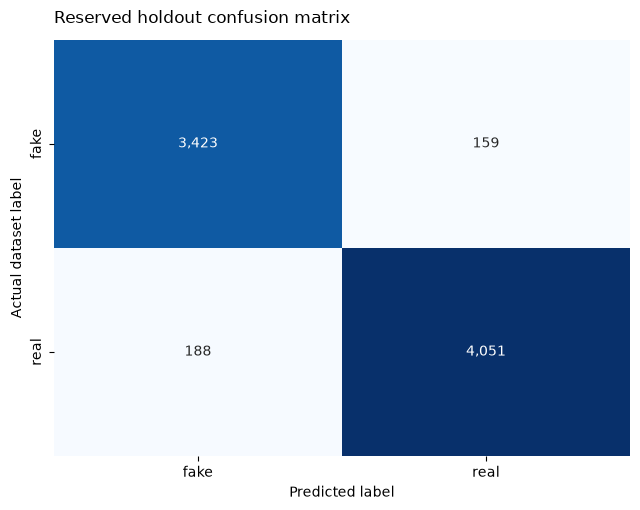

Misclassified articles: 347 of 7,821


,article_id,title,actual_label,predicted_label
35,3e37880a8c9ae6b0c37acf35b986eb96122683f18e4fd4...,SAUDI BILLIONAIRE Who Used Sharia Law To Make ...,fake,real
41,9ef9889cc48c4a0fdf74caa69e1e0ce19c7398908bd7c7...,Former Trump campaign staffer files discrimina...,real,fake
45,7dc7aee9af5cc52d4baceae3a1e12aa4a1c35e0cb235a2...,Celebrity U.S. presidential picks prompt allia...,real,fake
97,ea93c2947b8a3fb669f2aa91041082c3e8a7610157a150...,Briton in Trump gun incident could die in U.S....,real,fake
122,5a7c28a2ce054bd22ac7882ea887034f642da6488dfb61...,Hawaii lawmaker resigns from Republican Party ...,real,fake
155,ac13ffc03cad59e0c70deeb2e8102f1bc5e8f4075052c2...,"For Trump's defenders, White House turmoil is ...",real,fake
195,ef34f3175e59981b6961fa5422fe16d2aa2b118f39442a...,Topless Femen activist tries to snatch Jesus s...,real,fake
225,22504721661a4ed55fa778514ad3d9e724431ee320d284...,US Spends Over $500 Million To Train Syrian Re...,fake,real
237,b8de70d65b5fd5c7872df4cf0a67edcea649e1c9d19601...,"Daughter Chelsea casts Clinton as great mom, d...",real,fake
244,7ed7a600eeacac532a867eb768dde1cba1bf12aebba21b...,Canada pays tribute to billionaire couple afte...,real,fake


In [4]:
cm = confusion_matrix(y_true, y_pred, labels=labels)
fig, ax = plt.subplots(figsize=(6.5, 5.2))
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False,
            xticklabels=labels, yticklabels=labels, ax=ax)
ax.set_xlabel('Predicted label')
ax.set_ylabel('Actual dataset label')
ax.set_title('Reserved holdout confusion matrix', loc='left', pad=12)
fig.tight_layout()
plt.show()

misclassified = holdout.loc[y_true != y_pred, ['article_id', 'title', 'label']].copy()
misclassified = misclassified.rename(columns={'label': 'actual_label'})
misclassified['predicted_label'] = y_pred[y_true != y_pred]
print(f'Misclassified articles: {len(misclassified):,} of {len(holdout):,}')
display(misclassified.head(20))


## 5. Save the evaluation record

The aggregate JSON records metrics and context; the prediction CSV contains stable article IDs and labels, but not body text. These files document the single evaluation. Do not use the holdout results to pick a new configuration and then treat this same split as an untouched final test.


In [5]:
outputs_dir = PROJECT_ROOT / 'outputs'
outputs_dir.mkdir(parents=True, exist_ok=True)
metrics_path = outputs_dir / 'holdout_metrics.json'
predictions_path = outputs_dir / 'holdout_predictions.csv'

with metrics_path.open('w', encoding='utf-8') as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)
predictions = pd.DataFrame({
    'article_id': holdout['article_id'].to_numpy(),
    'actual_label': y_true,
    'predicted_label': y_pred,
})
predictions.to_csv(predictions_path, index=False)
print('Saved aggregate evaluation:', metrics_path)
print('Saved per-article predictions (no article text):', predictions_path)


Saved aggregate evaluation: C:\Projects_Tracking\News_Spam_Classifier\outputs\holdout_metrics.json
Saved per-article predictions (no article text): C:\Projects_Tracking\News_Spam_Classifier\outputs\holdout_predictions.csv


## 6. Conclusions and critique

The frozen BoW unigram ComplementNB pipeline (`min_df=2`, `alpha=0.01`) achieved holdout **macro F1 = 0.95534**, **accuracy = 0.95563**, macro precision **0.95508**, and macro recall **0.95563** on **7,821** reserved articles. Class metrics were: fake precision **0.9479**, recall **0.9556**, F1 **0.9518** (3,582 examples); real precision **0.9622**, recall **0.9556**, F1 **0.9589** (4,239 examples). The confusion matrix was actual fake → predicted fake/real: **3,423 / 159**; actual real → predicted fake/real: **188 / 4,051**. Overall, **347 (4.44%)** were misclassified.

Notebook 3's 5-fold CV macro F1 was **0.95609**, about **0.00075** above this holdout result. That close agreement is reassuring for random held-out examples from this same corpus; it is not evidence of external generalization, and these two scores are not interchangeable estimates.

### Interpretation boundary

This is a held-out evaluation for examples drawn randomly from the same dataset and labeling process, whose labels are assigned by source file rather than independently adjudicated article-by-article. It is not a fact-check of an article's claims. Source, topic, time period, and collection artifacts may be shared across the random split; subject-label confounding was especially strong in EDA even though `subject` was excluded from model inputs. The model made errors in both directions: 159 fake-labeled examples were called real, and 188 real-labeled examples were called fake. Strong holdout metrics therefore do not prove performance on newly published stories or unfamiliar publishers. Real-world assessment needs a separate, time-separated dataset with independent sources and carefully verified labels. Treat an individual prediction as a model classification, not a determination of truth.
